# Logistic Regression: From Probabilities to Decisions



### Learning Objectives

By the end of class, you should be able to:

- distinguish a classification problem from a regression problem;
- fit a logistic regression model with scikit-learn;
- interpret a predicted probability;
- explain how a decision threshold changes predictions;
- evaluate a classifier using a baseline and confusion matrix;
- identify which kinds of errors matter in a particular context.

### Group roles

Rotate roles after each activity:

- **Driver:** types and runs the code.
- **Navigator:** reads the prompt and documentation and suggests next steps.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import make_column_transformer
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

## 1. Human classifier: decide before you calculate

The dataset describes customers with a credit-card balance, annual income, student status, and whether they defaulted.

Before loading the real observations, consider the hypothetical customers below. With your group, **guess** `Yes` or `No` for each person using only the information in this table.

**Do not use the original dataset, code, or a formula yet.** These are informed human predictions, not answers with a hidden correct rule. Your goal is to expose the assumptions you make, identify the cases where you feel uncertain, and later compare your judgments with a fitted model.

In [9]:
hypothetical_customers = pd.DataFrame({
    "customer": ["A", "B", "C", "D", "E", "F"],
    "balance": [250, 900, 1400, 1750, 2050, 2350],
    "income": [18000, 72000, 38000, 95000, 42000, 110000],
    "student": ["Yes", "No", "Yes", "No", "Yes", "No"],
})

hypothetical_customers

,customer,balance,income,student
0,A,250,18000,Yes
1,B,900,72000,No
2,C,1400,38000,Yes
3,D,1750,95000,No
4,E,2050,42000,Yes
5,F,2350,110000,No


### Group prediction

Add your group's predictions and one sentence describing your rule.

- Which variable mattered most to you?
- Did you use a sharp cutoff?
- For which customer were you least certain?

In [10]:
# Replace the question marks with your group's Yes/No predictions.
hypothetical_customers["group_prediction"] = ["?", "?", "?", "?", "?", "?"]
hypothetical_customers

,customer,balance,income,student,group_prediction
0,A,250,18000,Yes,?
1,B,900,72000,No,?
2,C,1400,38000,Yes,?
3,D,1750,95000,No,?
4,E,2050,42000,Yes,?
5,F,2350,110000,No,?


> **Share-out:** Each group should report its prediction for Customer C or D. We will return to these cases after fitting a model.

## 2. Load and inspect the Default data

The response variable is `default`. This is a **classification** problem because the desired prediction is a category: `Yes` or `No`.

In [4]:
url = "https://raw.githubusercontent.com/jfkoehler/nyu_bootcamp_fa25/refs/heads/main/data/Default.csv"
default = pd.read_csv(url, index_col=0)
default.head()

,default,student,balance,income
1,No,No,729.526495,44361.625074
2,No,Yes,817.180407,12106.134700
3,No,No,1073.549164,31767.138947
4,No,No,529.250605,35704.493935
5,No,No,785.655883,38463.495879


### Activity 1 — Know what you are predicting

Work with your group to answer the following questions with pandas.

1. How many rows are in the dataset?
2. Are any values missing?
3. How many customers defaulted?
4. What proportion of customers did **not** default?
5. If a model always predicted the most common category, what accuracy would it achieve?

Assign one question to each group member, then combine your results.

In [ ]:
# Your exploration here


Record your baseline accuracy here:

> **Baseline accuracy:**  
> **Why it matters:**

### Activity 2 — Find a useful signal

Choose from predictors: `balance`, `income`, or `student`.

1. Create a visualization comparing your predictor with `default`.
2. Write one claim supported by the graph.
3. Identify one limitation of the graph.

Possible tools include `sns.boxplot`, `sns.histplot`, `sns.countplot`, and `sns.scatterplot`.

In [ ]:
# Create your group's visualization here.


## 3. Why not use ordinary linear regression?

We will first convert the outcome to zeroes and ones:

- `0` means no default;
- `1` means default.

In [5]:
default["default_binary"] = default["default"].map({"No": 0, "Yes": 1})
default[["default", "default_binary"]].head()

,default,default_binary
1,No,0
2,No,0
3,No,0
4,No,0
5,No,0


### Predict before running

Suppose we fit a straight line to `balance` and `default_binary`.

- What values could a straight line eventually predict?
- Why would a predicted value such as `-0.2` or `1.3` be a problem if it represented probability?
- Sketch the shape you think a probability model should have.

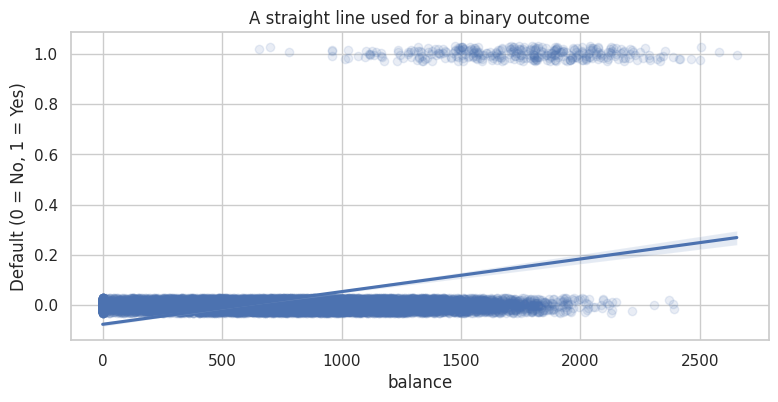

In [6]:
plt.figure(figsize=(9, 4))
sns.regplot(
    data=default,
    x="balance",
    y="default_binary",
    logistic=False,
    y_jitter=0.03,
    scatter_kws={"alpha": 0.12},
)
plt.title("A straight line used for a binary outcome")
plt.ylabel("Default (0 = No, 1 = Yes)");

### The logistic function

Logistic regression sends a linear expression through the sigmoid function:

$$
p(x)=\frac{1}{1+e^{-(\beta_0+\beta_1x)}}
$$

The result is always between 0 and 1, so it can be interpreted as a probability.

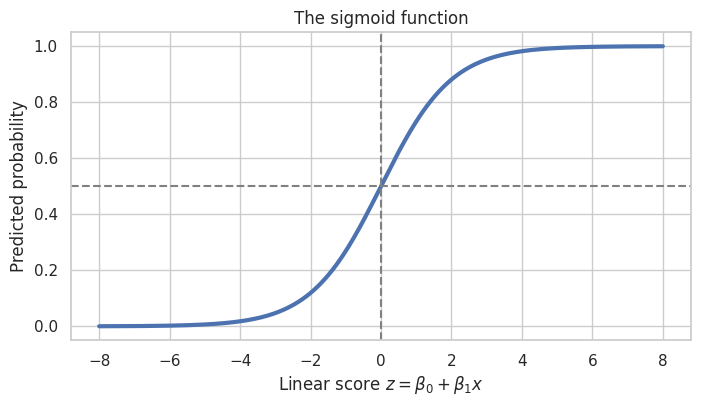

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 300)
plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z), linewidth=3)
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel(r"Linear score $z = \beta_0 + \beta_1x$")
plt.ylabel("Predicted probability")
plt.title("The sigmoid function");

### Turn and talk

1. What happens to the probability as the linear score becomes very positive?
2. What happens as it becomes very negative?
3. Where is the probability changing most rapidly?

## 4. Build a one-feature logistic regression model

Use `balance` to predict default. Follow the documentation rather than copying a completed model:

- [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

### Activity 3 — Complete the model

1. Define `X` using `balance` and `y` using `default_binary`.
2. Split the data using `random_state=42` and `stratify=y`.
3. Instantiate `LogisticRegression()`.
4. Fit it using the training data only.

In [ ]:
# Step 1: select feature and target
X = default[["balance"]]
y = default["default_binary"]

# Steps 2–4: complete the split, instantiate the model, and fit it
X_train, X_test, y_train, y_test = ...

model = ...
...

### Checkpoint

Before evaluating the model, make three predictions:

- Which customer should have the smallest estimated probability of default?
- Which should have the largest?
- At approximately what balance do you expect the probability to cross 50%?

In [ ]:
balances = pd.DataFrame({"balance": [500, 1500, 2500]})

# Use model.predict_proba(...) and keep the probability of class 1.
balances["probability_of_default"] = ...
balances

In [ ]:
# Plot the observations and the fitted probability curve.
grid = pd.DataFrame({"balance": np.linspace(default["balance"].min(),
                                             default["balance"].max(), 300)})
grid["probability"] = model.predict_proba(grid)[:, 1]

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=default,
    x="balance",
    y="default_binary",
    alpha=0.12,
)
plt.plot(grid["balance"], grid["probability"], color="crimson", linewidth=3)
plt.axhline(0.5, color="black", linestyle="--", label="0.50 threshold")
plt.ylabel("Observed outcome / predicted probability")
plt.legend();

### Interpret

Complete this sentence in ordinary language:

> For a customer with a balance of $1,500, the model estimates ____________.

## 5. A probability is not yet a decision

`predict_proba` produces probabilities. To create `Yes` or `No` predictions, we need a **decision threshold**. The usual default is 0.50, but that value is a choice rather than a law.

### Activity 4 — Threshold laboratory (15 minutes)

Run the next cell at several thresholds. Try at least `0.10`, `0.30`, `0.50`, and `0.70`.

In [ ]:
model.predict_proba(X_test)[:10]

In [11]:
def evaluate_threshold(threshold):
    predictions = (test_probabilities >= threshold).astype(int)
    results = pd.crosstab(
        y_test,
        predictions,
        rownames=["Actual"],
        colnames=["Predicted"],
        dropna=False,
    ).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

    tn, fp, fn, tp = results.to_numpy().ravel()
    return pd.Series({
        "threshold": threshold,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "true_negatives": tn,
    })

pd.DataFrame([evaluate_threshold(t) for t in [0.10, 0.30, 0.50, 0.70]])

NameError: name 'model' is not defined

In [14]:
# # Optional interactive slider. If widgets are unavailable, use the table above.
# import ipywidgets as widgets
# from IPython.display import display

# @widgets.interact(threshold=widgets.FloatSlider(
#     value=0.50, min=0.05, max=0.95, step=0.05,
#     description="Threshold"
# ))
# def threshold_display(threshold):
#     predictions = (test_probabilities >= threshold).astype(int)
#     ConfusionMatrixDisplay.from_predictions(y_test, predictions)
#     plt.show()
#     display(evaluate_threshold(threshold).to_frame("result"))


### Decision meeting

Imagine a financial counselor will contact every customer labeled as high risk.

Discuss:

1. What is a false positive in this setting?
2. What is a false negative?
3. Which error might be more costly to the customer? To the lender?
4. Which threshold would your group choose, and why?

> **Our threshold:**  
> **Our justification:**  
> **Who might be affected by this choice:**

## 6. Evaluation: accuracy can hide failure

Compare the fitted model with the baseline from Activity 1.

In [ ]:
test_predictions = model.predict(X_test)

print("Model test accuracy:", accuracy_score(y_test, test_predictions))
print("Baseline test accuracy:", y_test.value_counts(normalize=True).max())

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No default", "Default"],
    cmap="Blues",
)
plt.title("Test-set confusion matrix");

### Pair explanation

Your group must explain the confusion matrix without using only the word *accuracy*.

- How many actual defaults did the model detect?
- How many did it miss?
- Can a model have high accuracy and still perform poorly on the event we care about?

## 7. Return to the opening predictions

The opening task was a judgment exercise: there was no hidden formula and you were not expected to consult the dataset. Now use the fitted **balance-only** model to revisit those guesses.

1. Which of your original predictions changed?
2. Did the model resolve the case your group was least certain about?
3. What information did your group use that this model ignores?
4. Should we automatically trust the model over the group? Why or why not?

In [ ]:
opening_X = hypothetical_customers[["balance"]]
hypothetical_customers["model_probability"] = model.predict_proba(opening_X)[:, 1]
hypothetical_customers["model_prediction"] = model.predict(opening_X)
hypothetical_customers["model_prediction"] = hypothetical_customers["model_prediction"].map({0: "No", 1: "Yes"})
hypothetical_customers

## 8. Challenge: bank customer churn

The guided example asked whether a customer would default. Your group will now transfer the same workflow to a different business problem: **predicting whether a bank customer exits**.

The data come from the Bank Customer Churn dataset used in the original notebook. The target is `Exited`:

- `0`: the customer remained;
- `1`: the customer exited.

This is deliberately less scaffolded. Your group should decide what to inspect and how to explain the result.

In [12]:
bank_churn = fetch_openml(data_id=43390, as_frame=True).frame
bank_churn.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Churn investigation — first five minutes

Before modeling, answer:

1. How many customers and columns are present?
2. What proportion of customers exited?
3. Are any values missing?
4. Which variables are numerical and which are categorical?
5. Which feature do you predict will be most useful? Explain before testing it.

In [ ]:
# Inspect the churn data here.

### Build the churn model

Begin with the same features proposed in the original notebook:

- `CreditScore`
- `Gender`
- `Age`
- `Tenure`
- `Balance`

Your group must:

1. create `X` and `y`;
2. make a stratified train/test split with `random_state=11`;
3. one-hot encode `Gender`;
4. standardize the numerical features;
5. fit a logistic regression pipeline;
6. compare test accuracy with the majority-class baseline;
7. display and interpret the confusion matrix.

Use the linked scikit-learn documentation in the earlier section when you need help.

In [ ]:
features = ["CreditScore", "Gender", "Age", "Tenure", "Balance"]
numeric_features = ["CreditScore", "Age", "Tenure", "Balance"]
categorical_features = ["Gender"]

X = bank_churn[features]
y = pd.to_numeric(bank_churn["Exited"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=11,
    stratify=y,
)

churn_preprocessor = make_column_transformer(
    (OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
    (StandardScaler(), numeric_features),
)

churn_model = Pipeline([
    ("prepare", ...),
    ("model", ...),
])

# Fit the pipeline here.

In [ ]:
# Calculate the baseline and test accuracy.

In [ ]:
# Display the test-set confusion matrix.

### Choose one extension

After the basic model works, choose **one** extension:

**A. Add features**  
Add `Geography`, `NumOfProducts`, and `IsActiveMember`. Does performance improve?

**B. Change the threshold**  
Compare thresholds of 0.30 and 0.50. Which is better if the bank wants to identify more customers at risk of leaving?

**C. Investigate errors**  
Find the false negatives. What patterns do you notice in the customers the model failed to identify?

Your conclusion must include evidence, not merely a higher or lower score.

In [ ]:
# Extension workspace

### Two-minute group report

Prepare one speaker to report:

- **Question:** What did you investigate?
- **Evidence:** What result most influenced your conclusion?
- **Decision:** What would you recommend to the bank?
- **Caution:** What can this model not tell the bank?

## Exit Ticket

Respond to the questions [here](https://docs.google.com/forms/d/e/1FAIpQLSedMnZjZPhAGT6Hj8fjWdO8Pyjx-4jswAEXWpJN9uYqwVKlNg/viewform?usp=sharing&ouid=106596295392954890759).